# WindGuard: Exploratory Data Analysis
**Wind turbine failure precursor detection from SCADA data (Kelmarsh, Senvion MM92)**

This notebook is the data-preparation and EDA stage for a **single-fault precursor study focused on low hydraulic pressure**. Change the target in the configuration cell only after reviewing the event log. This notebook does not train or validate a predictive model. It is written to answer five questions that every later modelling stage depends on:

1. **Is the data trustworthy?** Coverage, timestamp regularity, missing values, frozen sensors.
2. **What is a "failure" here?** Which logged events count as failure anchors, and how many independent failure episodes exist.
3. **What does normal operation look like?** Power curve, operating regimes, thermal behaviour, turbine-to-turbine differences.
4. **Is there a real precursor?** Whether sensor behaviour 24 h before a failure is unusual *after removing the effect of load and weather*.
5. **What will the models be built on?** Window features, PCA, class imbalance, cross-farm channel overlap.

**Contents**
1. Setup and configuration
2. Data access and fleet loader
3. Data quality audit
4. Event-log analysis
5. Failure anchors, pre-failure labels and class imbalance
6. Operating behaviour: power curve, deviation feature, operating regimes
7. Thermal behaviour and sensor coupling
8. Sensor correlation and redundancy
9. Precursor analysis (normal-behaviour model + placebo test)
10. Window features
11. PCA and Kernel PCA
12. Distributions, seasonality, turbine-to-turbine offsets
13. Cross-farm channel overlap (Kelmarsh vs. Penmanshiel)
14. Leakage-safe evaluation design and modeling handoff
15. Summary of findings

*Run top to bottom. Review event candidates in Section 5, explicitly confirm the fault list, then restart and run all cells. The notebook stops before model training; it produces an evidence-based data and label handoff.*

## 1. Setup and configuration

In [1]:
import os, re, glob, json, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")

try:                                    # Colab: mount Drive (silently skipped elsewhere)
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

BASE = os.environ.get("WG_BASE", "/content/drive/MyDrive/WindGuard_Project")
FIG  = f"{BASE}/figures"
YEARS = list(range(2016, 2025))   # all Kelmarsh years; years missing from the Zenodo record are skipped with a warning.
                                  # The first run downloads several GB. Use YEARS = [2019] for a quick test.
DOWNLOAD_MISSING = True   # fetch missing Kelmarsh years / metadata / Penmanshiel sample from Zenodo
KELMARSH_RECORD, PENMANSHIEL_RECORD = "16807551", "16807304"

FAULT_MESSAGES = ["Low hydraulic pressure"]  # reviewed target event(s); edit only after reviewing Section 5
PRE_DAYS = 7              # hypothesis: predict this fault within the preceding N days
POST_BUFFER_DAYS = 1      # rows after a failure are not treated as "normal"
MIN_STOP_MIN = 5          # minimum event duration; confirm against the event-log semantics
CUT_IN, RATED_WS, RATED_P = 3.0, 12.5, 2050      # Senvion MM92 reference values
# Kelmarsh names these channels "..., StdDev", "..., Min", "..., Max" (older exports: "Standard deviation").
# The previous patterns (", Minimum"/", Maximum") matched nothing, so 264 columns were kept instead of ~99.
EXCLUDE_IN_NAME = (", StdDev", ", Standard deviation", ", Min", ", Max")   # keep mean channels only

# Vendor-derived KPI / energy / counter channels are not physical sensor readings. They are cumulative or computed
# from the status log (e.g. Lost Production to Downtime), so they inflate redundancy, dominate PCA and can leak status.
DROP_DERIVED = True
DERIVED_REGEX = (r"energy|lost production|potential power|capacity factor|counter|virtual production|"
                 r"equivalent full load|theoretical|avail|\((?:kwh|kvarh|mwh)\)")
DERIVED_RE = re.compile(DERIVED_REGEX, re.IGNORECASE)
DERIVED_DROPPED = set()

# "Healthy" rows (used for the power curve, regimes, normal-behaviour models and PCA) must not be downtime.
# Default: drop rows overlapping forced outage / maintenance / electrical-spec events and rows where the rotor is
# stationary despite usable wind. Set STRICT_FULL_PERFORMANCE=True to keep only IEC "Full Performance" intervals
# (this also removes low-wind standby, i.e. most of the below-cut-in regime).
STRICT_FULL_PERFORMANCE = False
DOWNTIME_IEC = {"Forced outage", "Scheduled Maintenance", "Out of Electrical Specification"}
STOP_WIND, STOP_RPM = 4.0, 1.0    # wind >= STOP_WIND m/s with rotor < STOP_RPM rpm = stopped, not healthy
MAX_EPISODE_PLOTS = 6
SEED = 42

os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})

def show(name):
    # Save the current figure for the report, then display it.
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close("all")

Mounted at /content/drive


## 2. Data access and fleet loader

Greenbyte exports start with `#` metadata lines, so the loader locates the real header row instead of hard-coding a line number. Only **mean** channels are kept (the `StdDev`, `Min`, `Max` variants are dropped). Vendor-derived KPI, energy and counter channels (`Energy…`, `Lost Production…`, `Potential power…`, `Capacity factor`, `…counter`) are dropped as well because they are computed or cumulative, not physical sensor readings. The loader prints how many channels remain and which derived channels were removed; the count should be close to the ~99 sensor variables the project plan refers to. Years missing from the Zenodo record are skipped with a warning.

In [5]:
import requests
HEAD = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept": "application/json",
    "Accept-Language": "en-US,en;q=0.9"
}

def zenodo_files(record):
    r = requests.get(f"https://zenodo.org/api/records/{record}", headers=HEAD, timeout=60)
    r.raise_for_status()
    return {f["key"]: f for f in r.json()["files"]}

def fetch(item, dest):
    if os.path.exists(dest) and os.path.getsize(dest) == item["size"]:
        return
    url = item["links"].get("content", item["links"]["self"])
    with requests.get(url, headers=HEAD, stream=True, timeout=(30, 300)) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for ch in r.iter_content(1 << 20):
                f.write(ch)

def ensure_year(year):
    d = f"{BASE}/extracted_scada_{year}"
    # If the local folder already contains turbine CSV data, use it directly without calling Zenodo
    if glob.glob(f"{d}/**/Turbine_Data_Kelmarsh_*.csv", recursive=True):
        return d
    if not DOWNLOAD_MISSING:
        raise FileNotFoundError(d)

    try:
        files = zenodo_files(KELMARSH_RECORD)
        key = next(k for k in files if k.startswith(f"Kelmarsh_SCADA_{year}") and k.endswith(".zip"))
        z = f"{BASE}/{key}"; fetch(files[key], z)
        os.makedirs(d, exist_ok=True)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(d)
        return d
    except Exception as e:
        # Fallback if Zenodo blocks us but a zip or folder already exists
        z = f"{BASE}/Kelmarsh_SCADA_{year}.zip"
        if os.path.exists(z):
            print(f"Zenodo request blocked, attempting to extract local archive: {z}")
            os.makedirs(d, exist_ok=True)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(d)
            return d
        raise RuntimeError(f"Failed to fetch Zenodo metadata and no local data found for year {year}: {e}")

def _header_idx(path, marker):
    with open(path, "r", errors="ignore") as f:
        for i, line in enumerate(f):
            if line.lstrip("# ").startswith(marker):
                return i
    raise ValueError(f"header '{marker}' not found in {path}")

def read_scada(path, mean_only=True):
    i = _header_idx(path, "Date and time")
    raw = pd.read_csv(path, skiprows=i, nrows=0).columns
    clean = [c.replace("# ", "").strip() for c in raw]
    keep = []
    for r, c in zip(raw, clean):
        if mean_only and any(s in c for s in EXCLUDE_IN_NAME):
            continue
        if DROP_DERIVED and DERIVED_RE.search(c):
            DERIVED_DROPPED.add(c); continue
        keep.append(r)
    df = pd.read_csv(path, skiprows=i, usecols=keep, low_memory=False)
    df.columns = [c.replace("# ", "").strip() for c in df.columns]
    df["Date and time"] = pd.to_datetime(df["Date and time"], errors="coerce")
    for c in df.columns:
        if c != "Date and time":
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float32")
    return df

def load_fleet(years):
    scada, status = [], []
    for y in years:
        try:
            d = ensure_year(y)
        except Exception as e:
            print(f"Year {y}: not available, skipped. Reason: {e}"); continue
        for p in sorted(glob.glob(f"{d}/**/Turbine_Data_Kelmarsh_*.csv", recursive=True)):
            t = int(re.search(r"Kelmarsh_(\d+)_", os.path.basename(p)).group(1))
            df = read_scada(p); df["turbine"] = t; df["year"] = y
            scada.append(df)
        for p in sorted(glob.glob(f"{d}/**/Status_Kelmarsh_*.csv", recursive=True)):
            t = int(re.search(r"Kelmarsh_(\d+)_", os.path.basename(p)).group(1))
            s = pd.read_csv(p, comment="#", skipinitialspace=True); s["turbine"] = t
            status.append(s)
    if not scada:
        raise RuntimeError("No SCADA data could be loaded. Zenodo was blocked and no extracted data was found in your Drive.")
    scada = pd.concat(scada, ignore_index=True)
    status = pd.concat(status, ignore_index=True)
    status["Timestamp start"] = pd.to_datetime(status["Timestamp start"], errors="coerce")
    status["Timestamp end"] = pd.to_datetime(status["Timestamp end"], errors="coerce")
    status["dur_min"] = pd.to_timedelta(status["Duration"], errors="coerce").dt.total_seconds() / 60
    status["Status"] = status["Status"].fillna("")
    status["Message"] = status["Message"].fillna("")
    return scada, status

scada, status = load_fleet(YEARS)
scada  = scada.sort_values(["turbine", "Date and time"]).reset_index(drop=True)
status = status.sort_values(["turbine", "Timestamp start"]).reset_index(drop=True)
RAW_SENSORS = [c for c in scada.columns if c not in ("Date and time", "turbine", "year")]

def pick(*cands):
    return next((c for c in cands if c in scada.columns), None)

WIND  = pick("Wind speed (m/s)");  POWER = pick("Power (kW)")
ROTOR = pick("Rotor speed (RPM)"); AMB   = pick("Nacelle ambient temperature (°C)")
GEAR  = pick("Gear oil temperature (°C)"); BEAR = pick("Front bearing temperature (°C)")
TARGETS = [c for c in ["Gear oil temperature (°C)", "Front bearing temperature (°C)",
                       "Generator bearing front temperature (°C)", "Stator temperature 1 (°C)"]
           if c in scada.columns]
CORE = [c for c in ["Wind speed (m/s)", "Power (kW)", "Blade angle (pitch position) A (°)", "Rotor speed (RPM)",
                    "Generator RPM (RPM)", "Gear oil temperature (°C)", "Front bearing temperature (°C)",
                    "Generator bearing front temperature (°C)", "Stator temperature 1 (°C)",
                    "Transformer temperature (°C)", "Nacelle ambient temperature (°C)",
                    "Gear oil inlet pressure (bar)", "Tower Acceleration X (mm/ss)"] if c in scada.columns]

# Optional turbine metadata and signal mapping from the Zenodo record
if DOWNLOAD_MISSING:
    try:
        files = zenodo_files(KELMARSH_RECORD)
        for key in ["Kelmarsh_WT_static.csv", "Kelmarsh_WT_dataSignalMapping.csv"]:
            if key in files:
                fetch(files[key], f"{BASE}/{key}")
        print("Turbine metadata (static):")
        display(pd.read_csv(f"{BASE}/Kelmarsh_WT_static.csv", comment="#", on_bad_lines="skip").head(8))
    except Exception as e:
        print("Metadata skipped:", repr(e)[:120])

print(f"\nSCADA rows: {len(scada):,} | mean-only sensor channels: {len(RAW_SENSORS)} | turbines: {scada.turbine.nunique()} | years: {sorted(scada.year.unique().tolist())}")
print(f"Derived KPI/energy/counter channels dropped: {len(DERIVED_DROPPED)}")
print("  " + "; ".join(sorted(DERIVED_DROPPED)[:40]) + (" ..." if len(DERIVED_DROPPED) > 40 else ""))
fleet = scada.groupby("turbine").agg(rows=("Date and time", "size"),
                                     start=("Date and time", "min"), end=("Date and time", "max"))
fleet["expected_rows"] = ((fleet.end - fleet.start) / pd.Timedelta(minutes=10)).round().astype(int) + 1
fleet["missing_ts"] = fleet.expected_rows - fleet.rows
fleet["dup_ts"] = scada.duplicated(["turbine", "Date and time"]).groupby(scada["turbine"]).sum()
fleet["irregular_steps"] = scada.groupby("turbine")["Date and time"].apply(
    lambda s: int((s.diff().dropna() != pd.Timedelta(minutes=10)).sum()))
display(fleet)

Year 2016: not available, skipped. Reason: Failed to fetch Zenodo metadata and no local data found for year 2016: 403 Client Error: Forbidden for url: https://zenodo.org/api/records/16807551
Year 2017: not available, skipped. Reason: Failed to fetch Zenodo metadata and no local data found for year 2017: 403 Client Error: Forbidden for url: https://zenodo.org/api/records/16807551
Year 2018: not available, skipped. Reason: Failed to fetch Zenodo metadata and no local data found for year 2018: 403 Client Error: Forbidden for url: https://zenodo.org/api/records/16807551
Year 2020: not available, skipped. Reason: Failed to fetch Zenodo metadata and no local data found for year 2020: 403 Client Error: Forbidden for url: https://zenodo.org/api/records/16807551
Year 2021: not available, skipped. Reason: Failed to fetch Zenodo metadata and no local data found for year 2021: 403 Client Error: Forbidden for url: https://zenodo.org/api/records/16807551
Year 2022: not available, skipped. Reason: Fa

,rows,start,end,expected_rows,missing_ts,dup_ts,irregular_steps
turbine,,,,,,,
1,52560,2019-01-01,2019-12-31 23:50:00,52560,0,0,0
2,52560,2019-01-01,2019-12-31 23:50:00,52560,0,0,0
3,52560,2019-01-01,2019-12-31 23:50:00,52560,0,0,0
4,52560,2019-01-01,2019-12-31 23:50:00,52560,0,0,0
5,52560,2019-01-01,2019-12-31 23:50:00,52560,0,0,0
6,52560,2019-01-01,2019-12-31 23:50:00,52560,0,0,0


## 3. Data quality audit

**What to look for:** timestamp gaps or duplicates (table above), channels with many missing values, whether missing values form one contiguous outage, and sensors that stay frozen at a constant value. Frozen runs matter because a flat sensor looks "stable" to a model but carries no information.

In [6]:
def runs_of_true(mask):
    m = np.r_[False, np.asarray(mask, dtype=bool), False]
    d = np.diff(m.astype(int))
    return np.where(d == 1)[0], np.where(d == -1)[0]          # [start, end)

nan_pct = scada.groupby("turbine")[RAW_SENSORS].apply(lambda g: g.isna().mean() * 100)
worst = nan_pct.max().sort_values(ascending=False).head(15)
print("Channels with the highest missing-value share (% per turbine):")
display(nan_pct[worst.index].round(2))

all_nan = [c for c in RAW_SENSORS if scada[c].isna().all()]
const   = [c for c in RAW_SENSORS if scada[c].nunique(dropna=True) <= 1 and c not in all_nan]
print(f"All-NaN channels: {len(all_nan)} | constant channels: {len(const)} | channels with >20% NaN on any turbine: {(nan_pct.max() > 20).sum()}")

print(f"\nLongest missing runs in '{GEAR}' (one contiguous outage, or scattered?):")
for t, g in scada.groupby("turbine"):
    g = g.reset_index(drop=True)
    s, e = runs_of_true(g[GEAR].isna())
    for k in np.argsort(e - s)[::-1][:2]:
        print(f"  T{t}: {g['Date and time'][s[k]]} -> {g['Date and time'][e[k]-1]}  ({e[k]-s[k]} steps)")

print(f"\nFrozen '{ROTOR}' runs >= 36 steps (6 h) and the turbine state during them:")
for t, g in scada.groupby("turbine"):
    g = g.reset_index(drop=True)
    s, e = runs_of_true((g[ROTOR].diff() == 0) & g[ROTOR].notna())
    for k in [k for k in np.argsort(e - s)[::-1][:2] if e[k] - s[k] >= 36]:
        seg = g.iloc[s[k]:e[k]]
        print(f"  T{t}: {seg['Date and time'].iloc[0]} -> {seg['Date and time'].iloc[-1]} "
              f"({e[k]-s[k]+1} steps, {seg[ROTOR].iloc[0]:.2f} rpm, wind {seg[WIND].mean():.1f} m/s, power {seg[POWER].mean():.0f} kW)")

def max_run(mask):
    s, e = runs_of_true(mask); return int((e - s).max()) + 1 if len(s) else 0

audit = []
for ch in CORE:
    audit.append({"channel": ch,
                  "missing_%": round(scada[ch].isna().mean() * 100, 2),
                  "zero_%": round((scada[ch] == 0).mean() * 100, 2),
                  "max_frozen_steps": max(max_run(g[ch].diff().eq(0) & g[ch].notna()) for _, g in scada.groupby("turbine"))})
print("\nCore-channel audit (fleet):"); display(pd.DataFrame(audit))

Channels with the highest missing-value share (% per turbine):


,"Hub temperature, standard deviation (°C)","Hub temperature, max (°C)","Hub temperature, min (°C)","Current L3 / W, min (A)","Current L2 / V, min (A)","Current L2 / V, max (A)","Current L3 / W, max (A)","Generator bearing front temperature, Std (°C)","Generator bearing rear temperature, Std (°C)",Production-based IEC B.2.3 (Users View),Current L3 / W (A),"Current L1 / U, min (A)",Turbine Power setpoint (kW),Vane position 1+2 (°),Tower Acceleration y (mm/ss)
turbine,,,,,,,,,,,,,,,
1,50.64,50.64,50.64,50.62,50.62,50.06,50.06,24.42,24.42,12.59,4.62,4.62,4.62,4.62,4.62
2,50.63,50.63,50.63,50.61,50.61,50.05,50.05,19.97,19.97,10.65,0.14,0.14,0.14,0.14,0.14
3,50.64,50.64,50.64,50.61,50.61,50.06,50.06,19.97,19.97,12.15,0.14,0.14,0.14,0.14,0.14
4,50.59,50.59,50.59,50.57,50.57,50.01,50.01,19.92,19.92,10.95,0.10,0.10,0.10,0.10,0.10
5,50.64,50.64,50.64,50.62,50.62,50.06,50.06,19.97,19.97,13.17,0.16,0.16,0.16,0.16,0.16
6,50.60,50.60,50.60,50.57,50.57,50.01,50.01,19.93,19.93,14.10,0.10,0.10,0.10,0.10,0.10


All-NaN channels: 0 | constant channels: 0 | channels with >20% NaN on any turbine: 9

Longest missing runs in 'Gear oil temperature (°C)' (one contiguous outage, or scattered?):
  T1: 2019-05-05 03:20:00 -> 2019-05-21 09:50:00  (2344 steps)
  T1: 2019-11-05 10:20:00 -> 2019-11-05 15:30:00  (32 steps)
  T2: 2019-11-04 11:30:00 -> 2019-11-04 16:20:00  (30 steps)
  T2: 2019-11-15 06:30:00 -> 2019-11-15 10:30:00  (25 steps)
  T3: 2019-11-04 11:30:00 -> 2019-11-04 16:20:00  (30 steps)
  T3: 2019-11-05 10:20:00 -> 2019-11-05 15:00:00  (29 steps)
  T4: 2019-11-04 11:30:00 -> 2019-11-04 16:20:00  (30 steps)
  T4: 2019-01-21 14:50:00 -> 2019-01-21 15:30:00  (5 steps)
  T5: 2019-11-04 11:30:00 -> 2019-11-04 16:20:00  (30 steps)
  T5: 2019-11-05 10:20:00 -> 2019-11-05 15:00:00  (29 steps)
  T6: 2019-11-04 11:30:00 -> 2019-11-04 17:20:00  (36 steps)
  T6: 2019-01-21 14:50:00 -> 2019-01-21 15:30:00  (5 steps)

Frozen 'Rotor speed (RPM)' runs >= 36 steps (6 h) and the turbine state during them:
  T

,channel,missing_%,zero_%,max_frozen_steps
0,Wind speed (m/s),0.13,0.00,2
1,Power (kW),0.13,0.00,3
2,Blade angle (pitch position) A (°),0.88,45.28,340
3,Rotor speed (RPM),0.13,2.23,121
4,Generator RPM (RPM),0.13,0.02,26
5,Gear oil temperature (°C),0.88,0.00,3
6,Front bearing temperature (°C),0.88,0.00,18
7,Generator bearing front temperature (°C),0.13,0.00,30
8,Stator temperature 1 (°C),0.13,0.00,27
9,Transformer temperature (°C),0.88,0.00,3


## 4. Event-log analysis

The status log is the only source of failure labels, so it needs to be understood before anything is labelled. The questions are: how many events exist, how many are routine (battery tests, cable unwinding, manual stops), and which messages could represent a real component fault.

Status counts per turbine:


Status,Communication,Informational,Stop,Warning
turbine,,,,
1,10,7606,118,87
2,8,7610,112,100
3,9,11728,110,55
4,12,8647,118,61
5,10,8971,114,68
6,9,13520,101,142



IEC category:


,count
IEC category,
Full Performance,36010
Out of Environmental Specification,13424
Technical Standby,9363
NaN,277
Forced outage,146
Scheduled Maintenance,64
Out of Electrical Specification,42



Service contract category:


,count
Service contract category,
NaN,44101
System OK (32),7148
External stop (low wind speed) (5),6396
Operating states (28),904
Warnings (27),519
Manual stop (service) (9),138
External stop (grid) (4),35
Safety stop of WEC (15),33
Remote stop (30),16



Top stop reasons (fleet-wide):


,n,turbines,med_dur_min,total_h
Message,,,,
Battery test,299,6,2.30,11.89
Cable autounwind,122,6,12.72,30.59
Hydraulic oil flushing operation,56,6,10.02,9.35
Manual stop - on site,51,6,63.83,102.88
Grid loss,23,6,3.40,2.67
Manual stop - remote,16,6,269.43,55.91
Tower oscillation X level 2,14,5,15.66,3.19
Frequency converter not ready,14,6,2.00,16.66
Manual stop without login,11,6,81.07,13.90


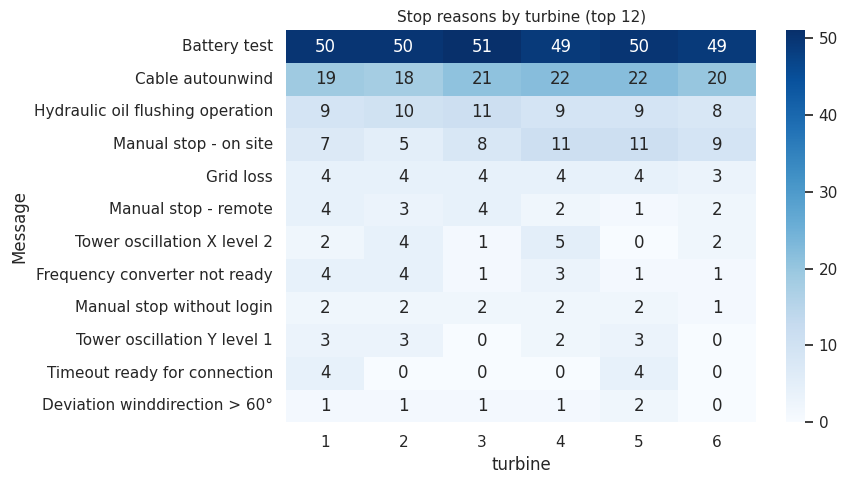

Top warning messages:


,count
Message,
High yaw motor current,195
Timeout brake closed,38
Battery charge cycle axis 1 error,38
Battery charge cycle axis 3 error,38
Battery charge cycle axis 2 error,38
Overload generator fan 2,23
Overload generator fan 1,23
Brake accumulator defect,23
Overload generator fan 3,23


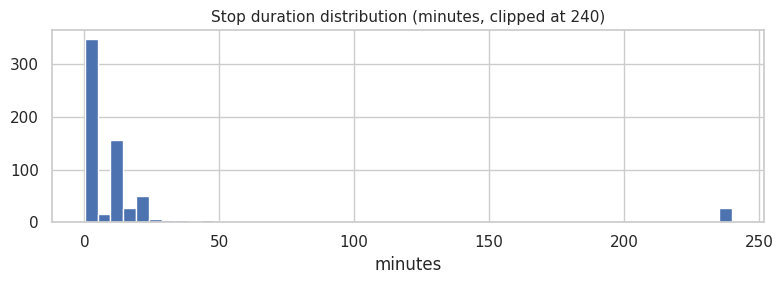

In [7]:
print("Status counts per turbine:")
display(pd.crosstab(status.turbine, status.Status))

for col in ["IEC category", "Service contract category"]:
    if col in status.columns:
        print(f"\n{col}:"); display(status[col].value_counts(dropna=False).head(12))

stops = status[status.Status.str.lower() == "stop"]
top = (stops.groupby("Message")
       .agg(n=("turbine", "size"), turbines=("turbine", "nunique"),
            med_dur_min=("dur_min", "median"), total_h=("dur_min", lambda x: x.sum() / 60))
       .sort_values("n", ascending=False).head(20).round(2))
print("\nTop stop reasons (fleet-wide):"); display(top)

plt.figure(figsize=(9, 5))
sns.heatmap(pd.crosstab(stops.Message, stops.turbine).loc[top.index[:12]], annot=True, fmt="d", cmap="Blues")
plt.title("Stop reasons by turbine (top 12)"); show("04_stop_reasons_by_turbine")

warns = status[status.Status.str.lower() == "warning"]
print("Top warning messages:"); display(warns.Message.value_counts().head(15))

stops.dur_min.dropna().clip(upper=240).hist(bins=50, figsize=(8, 3))
plt.title("Stop duration distribution (minutes, clipped at 240)"); plt.xlabel("minutes"); show("04_stop_duration")

## 5. Failure anchors, pre-failure labels and class imbalance

**Manual step.** The regular expressions below only *propose* fault-like messages. Review the candidate table and confirm `FAULT_MESSAGES` in Section 1. The configured list is explicit and is never inferred automatically. Confirm that chosen messages denote component failures rather than operational stops, and record the rationale. Routine stops (battery test, cable unwind, manual stops, flushing) are deliberately excluded.

Each failure episode is anchored at the start of its first qualifying stop. Events closer than `PRE_DAYS` are merged into one episode so that a single degradation is not counted twice. Rows in the half-open interval `[t_fail - PRE_DAYS, t_fail)` get `label = 1`; this is a prediction-window hypothesis, not a known physical lead time; rows during the stop and the following `POST_BUFFER_DAYS` are flagged `excluded` so they never pollute the "normal" class.

**Healthy rows.** `healthy_mask` (used by every "normal behaviour" step below) is the strict version of "normal": not pre-failure, not in the post-failure buffer, not inside a forced-outage / maintenance / electrical-spec interval of the status log, not stationary at usable wind (`STOP_WIND`, `STOP_RPM`), and with wind, power, rotor speed, ambient and the target temperatures all present.

Fault-like candidates (REVIEW, then edit FAULT_MESSAGES):


n  turbines  med_dur_min
Status  Message                                                             
Warning High yaw motor current                    195         6     0.183333
        Overload generator fan 2                   23         6    78.050000
        Overload generator fan 1                   23         6    78.066667
        Overload generator fan 3                   23         6    77.983333
        Easy yaw                                   18         6     0.958333
        Overload generator heating                 14         6    89.425000
Stop    Frequency converter not ready              14         6     2.000000
        Low hydraulic pressure                      2         1     8.075000
        Service generator brushes                   2         2   286.250000
        Uncontrolled yaw movement                   1         1     5.733333
        Yaw speed high                              1         1     5.666667
Warning Overload transformer fan outlet air         1         1    30.366667
        PT100 converter inlet temperature defect    1         1    31.483333
        Pitch batteries charging cycle              1         1     3.433333
        Reduced power converter                     1         1    30.766667


Explicit reviewed FAULT_MESSAGES in use: ['Low hydraulic pressure']

Failure episodes (events within 7 d merged): 2


,turbine,t_fail,t_end,message
0,1,2019-02-24 02:31:49,2019-02-24 02:39:36,Low hydraulic pressure
1,1,2019-03-27 20:32:14,2019-03-27 20:40:36,Low hydraulic pressure



Healthy-row definition (downtime events ['Forced outage', 'Out of Electrical Specification', 'Scheduled Maintenance']):
  not pre-failure / not post-failure buffer : 313,055
  removed: inside downtime event            : 1,931
  removed: rotor < 1.0 rpm at wind >= 4.0 m/s   : 1,365
  removed: key sensors missing              : 2,762
  healthy rows kept                         : 308,580 of 315,360


,rows,pre_failure_rows,excluded_rows,episodes,pos_share_%
turbine,,,,,
1,52560,2016,289,2,3.836
2,52560,0,0,0,0.000
3,52560,0,0,0,0.000
4,52560,0,0,0,0.000
5,52560,0,0,0,0.000
6,52560,0,0,0,0.000


Pre-failure rows: 2,016 of 315,360  ->  imbalance ≈ 1 : 155
Label-window sensitivity:


,PRE_DAYS,positive_rows,positive_share_%
0,3,864,0.274
1,7,2016,0.639
2,14,4032,1.279
3,30,8640,2.740


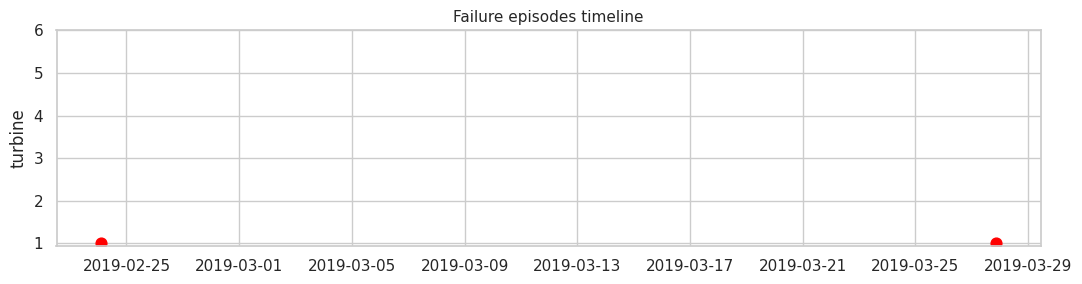


GATE: only 2 episodes -> too few for reliable supervised models, RUL regression or bootstrap CIs.
  Options: (a) add more Kelmarsh years (YEARS=...), (b) use the EDP 28-event logbook as a primary source,
  (c) lead with anomaly detection / normal-behaviour modelling and report classification as secondary.
Saved labelled dataset and episode table to Drive.


In [8]:
ROUTINE_REGEX = r"battery test|autounwind|flushing|manual|grid loss|timeout|icing|wind ?direction"
FAULT_REGEX   = r"hydraulic pressure|gearbox|gear oil|generator|bearing|pitch|yaw|over ?temp|temperature|vibration|converter|transformer|blade"

cand = status[status.Status.str.lower().isin(["stop", "warning"])].copy()
cand["is_routine"] = cand.Message.str.contains(ROUTINE_REGEX, case=False, regex=True)
cand["fault_like"] = cand.Message.str.contains(FAULT_REGEX, case=False, regex=True) & ~cand.is_routine
review = (cand[cand.fault_like].groupby(["Status", "Message"])
          .agg(n=("turbine", "size"), turbines=("turbine", "nunique"), med_dur_min=("dur_min", "median"))
          .sort_values("n", ascending=False))
print("Fault-like candidates (REVIEW, then edit FAULT_MESSAGES):"); display(review)

_r = review.reset_index()
print("\nExplicit reviewed FAULT_MESSAGES in use:", FAULT_MESSAGES)
if not FAULT_MESSAGES:
    raise ValueError("Set FAULT_MESSAGES in Section 1 after reviewing the candidate table. Do not label automatically.")
unknown = sorted(set(FAULT_MESSAGES) - set(cand.Message))
if unknown:
    raise ValueError(f"Configured messages were not found in the event log: {unknown}")

anchors = status[(status.Status.str.lower() == "stop") & status.Message.isin(FAULT_MESSAGES)
                 & (status.dur_min >= MIN_STOP_MIN)].sort_values(["turbine", "Timestamp start"])
eps = []
for t, g in anchors.groupby("turbine"):
    last = None
    for _, r in g.iterrows():
        if last is None or r["Timestamp start"] - last > pd.Timedelta(days=PRE_DAYS):
            end = r["Timestamp end"] if pd.notna(r["Timestamp end"]) else r["Timestamp start"]
            eps.append(dict(turbine=t, t_fail=r["Timestamp start"], t_end=end, message=r["Message"]))
        last = r["Timestamp start"]
episodes = (pd.DataFrame(eps, columns=["turbine", "t_fail", "t_end", "message"])
            .sort_values(["turbine", "t_fail"]).reset_index(drop=True))
print(f"\nFailure episodes (events within {PRE_DAYS} d merged): {len(episodes)}")
display(episodes)

def build_labels(df, episodes, pre_days=PRE_DAYS, post_days=POST_BUFFER_DAYS):
    out = df[["turbine", "Date and time"]].copy()
    out["label"] = 0; out["episode_id"] = -1; out["excluded"] = False
    t = out["Date and time"]
    for eid, ep in episodes.iterrows():
        m = out.turbine == ep.turbine
        pre  = m & (t >= ep.t_fail - pd.Timedelta(days=pre_days)) & (t < ep.t_fail)
        post = m & (t >= ep.t_fail) & (t < ep.t_end + pd.Timedelta(days=post_days))
        out.loc[pre, "label"] = 1; out.loc[pre, "episode_id"] = eid
        out.loc[post, "excluded"] = True
    return out

lab = build_labels(scada, episodes)
scada["label"], scada["episode_id"], scada["excluded"] = lab.label, lab.episode_id, lab.excluded

# --- healthy-row definition: exclude downtime, stopped rotor at usable wind, and rows with missing key sensors ---
def rows_in_intervals(df, ev, step=pd.Timedelta(minutes=10)):
    """Boolean array: SCADA rows (10-min, stamped at interval start) overlapping any event [start, end). df must be sorted by turbine, time."""
    out = np.zeros(len(df), dtype=bool)
    tvals, turb = df["Date and time"].values, df["turbine"].values
    for t, g in ev.dropna(subset=["Timestamp start", "Timestamp end"]).groupby("turbine"):
        idx = np.flatnonzero(turb == t); tt = tvals[idx]
        lo = np.searchsorted(tt, (g["Timestamp start"] - step).values, side="right")
        hi = np.searchsorted(tt, g["Timestamp end"].values, side="left")
        for a, b in zip(lo, hi):
            if b > a:
                out[idx[a:b]] = True
    return out

iec = status["IEC category"].fillna("") if "IEC category" in status.columns else pd.Series("", index=status.index)
down_ev = status[(iec != "") & (iec != "Full Performance")] if STRICT_FULL_PERFORMANCE else status[iec.isin(DOWNTIME_IEC)]
scada["downtime"] = rows_in_intervals(scada, down_ev)
scada["stopped_at_wind"] = ((scada[WIND] >= STOP_WIND) & (scada[ROTOR] < STOP_RPM)).fillna(False)
HEALTHY_REQ = [c for c in [WIND, POWER, ROTOR, AMB] + TARGETS if c]
has_keys = scada[HEALTHY_REQ].notna().all(axis=1)
base_ok = (scada.label == 0) & (~scada.excluded)
healthy_mask = base_ok & (~scada.downtime) & (~scada.stopped_at_wind) & has_keys
print(f"\nHealthy-row definition ({'IEC Full Performance only' if STRICT_FULL_PERFORMANCE else 'downtime events ' + str(sorted(DOWNTIME_IEC))}):")
print(f"  not pre-failure / not post-failure buffer : {int(base_ok.sum()):,}")
print(f"  removed: inside downtime event            : {int((base_ok & scada.downtime).sum()):,}")
print(f"  removed: rotor < {STOP_RPM} rpm at wind >= {STOP_WIND} m/s   : {int((base_ok & scada.stopped_at_wind).sum()):,}")
print(f"  removed: key sensors missing              : {int((base_ok & ~has_keys).sum()):,}")
print(f"  healthy rows kept                         : {int(healthy_mask.sum()):,} of {len(scada):,}")

summary = scada.groupby("turbine").agg(rows=("label", "size"), pre_failure_rows=("label", "sum"), excluded_rows=("excluded", "sum"))
summary["episodes"] = episodes.groupby("turbine").size().reindex(summary.index).fillna(0).astype(int)
summary["pos_share_%"] = (summary.pre_failure_rows / summary.rows * 100).round(3)
display(summary)
pos = int(scada.label.sum())
print(f"Pre-failure rows: {pos:,} of {len(scada):,}  ->  imbalance ≈ 1 : {(len(scada)-pos)/max(pos,1):,.0f}")

sens = [dict(PRE_DAYS=n, positive_rows=int(build_labels(scada, episodes, pre_days=n).label.sum())) for n in [3, 7, 14, 30]]
sens = pd.DataFrame(sens); sens["positive_share_%"] = (sens.positive_rows / len(scada) * 100).round(3)
print("Label-window sensitivity:"); display(sens)

if len(episodes):
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.scatter(episodes.t_fail, episodes.turbine, c="red", s=60)
    ax.set_yticks(sorted(scada.turbine.unique())); ax.set_ylabel("turbine"); ax.set_title("Failure episodes timeline")
    show("05_failure_timeline")

n_ep = len(episodes)
REF_T = int(episodes.turbine.value_counts().idxmax()) if n_ep else int(scada.turbine.min())   # turbine used for single-turbine plots
if n_ep >= 20:
    print(f"\nGATE: {n_ep} episodes -> supervised classification is plausible (use turbine-wise / chronological splits).")
else:
    print(f"\nGATE: only {n_ep} episodes -> too few for reliable supervised models, RUL regression or bootstrap CIs.\n"
          "  Options: (a) add more Kelmarsh years (YEARS=...), (b) use the EDP 28-event logbook as a primary source,\n"
          "  (c) lead with anomaly detection / normal-behaviour modelling and report classification as secondary.")
try:
    scada.to_parquet(f"{BASE}/scada_labelled.parquet"); episodes.to_csv(f"{BASE}/failure_episodes.csv", index=False)
    print("Saved labelled dataset and episode table to Drive.")
except Exception as e:
    print("Could not save parquet (pip install pyarrow):", e)

## 6. Operating behaviour

### 6.1 Power curve and the power-curve-deviation feature
The turbine's empirical power curve is the most basic health reference: for a given wind speed, power should follow a stable curve. The curve below is built from **healthy rows of all turbines** (median per 0.5 m/s wind bin). Its row-wise difference to actual power, `power_dev`, is one of the engineered features required by the project plan.

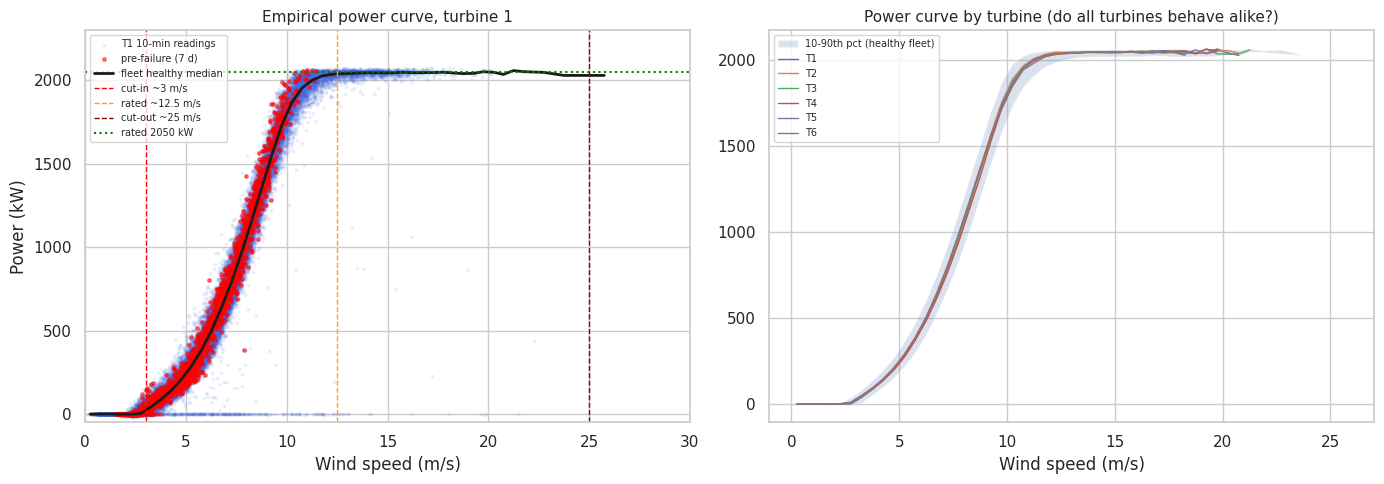

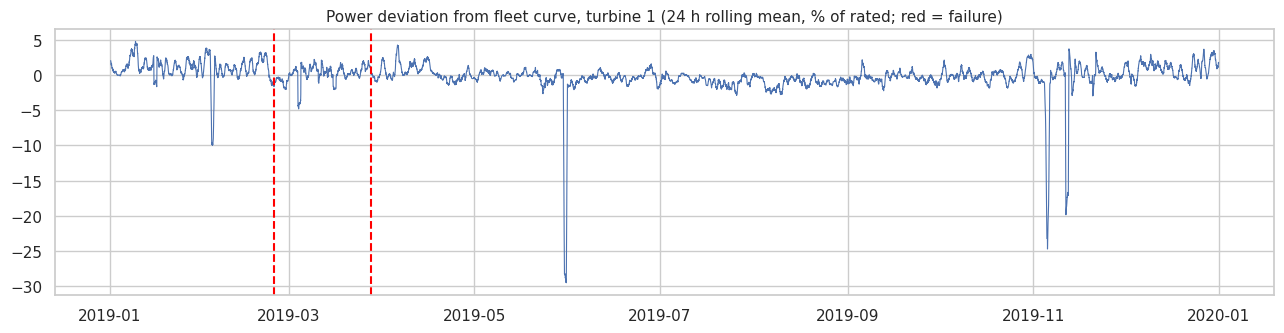

In [9]:
h = scada[healthy_mask & scada[WIND].between(0, 30)].copy()
bins = np.arange(0, 26.5, 0.5); centers = bins[:-1] + 0.25
h["wbin"] = pd.cut(h[WIND], bins)
def binned(q):
    return h.groupby("wbin", observed=False)[POWER].quantile(q).interpolate().bfill().ffill().values
pc, lo, hi = binned(0.5), binned(0.1), binned(0.9)

scada["power_expected"] = np.interp(scada[WIND], centers, pc)
scada["power_dev"] = scada[POWER] - scada["power_expected"]
scada["power_dev_pct"] = scada["power_dev"] / RATED_P * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
t1 = scada[scada.turbine == REF_T]
ax[0].scatter(t1[WIND], t1[POWER], s=3, alpha=0.08, c="royalblue", label=f"T{REF_T} 10-min readings")
pre = t1[t1.label == 1]
if len(pre):
    ax[0].scatter(pre[WIND], pre[POWER], s=6, alpha=0.5, c="red", label=f"pre-failure ({PRE_DAYS} d)")
ax[0].plot(centers, pc, "k", lw=2, label="fleet healthy median")
for x, c, l in [(CUT_IN, "red", "cut-in ~3 m/s"), (RATED_WS, "orange", "rated ~12.5 m/s"), (25, "darkred", "cut-out ~25 m/s")]:
    ax[0].axvline(x, color=c, ls="--", lw=1, label=l)
ax[0].axhline(RATED_P, color="green", ls=":", label="rated 2050 kW")
ax[0].set_xlim(0, 30); ax[0].set_ylim(-50, 2300); ax[0].set_xlabel("Wind speed (m/s)"); ax[0].set_ylabel("Power (kW)")
ax[0].set_title(f"Empirical power curve, turbine {REF_T}"); ax[0].legend(fontsize=7, loc="upper left")

ax[1].fill_between(centers, lo, hi, alpha=0.2, label="10-90th pct (healthy fleet)")
for t, g in h.groupby("turbine"):
    ax[1].plot(centers, g.groupby("wbin", observed=False)[POWER].median().values, lw=1, label=f"T{t}")
ax[1].set_title("Power curve by turbine (do all turbines behave alike?)"); ax[1].set_xlabel("Wind speed (m/s)"); ax[1].legend(fontsize=7)
show("06_power_curve")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(t1["Date and time"], t1.power_dev_pct.rolling(144, min_periods=50).mean(), lw=0.8)
for _, ep in episodes[episodes.turbine == REF_T].iterrows():
    ax.axvline(ep.t_fail, color="red", ls="--")
ax.set_title(f"Power deviation from fleet curve, turbine {REF_T} (24 h rolling mean, % of rated; red = failure)")
show("06_power_deviation")

### 6.2 Operating-regime clustering
A turbine's normal sensor behaviour differs strongly by regime, so models should be judged within a regime. The number of clusters is **chosen with evidence** (elbow and silhouette), and K-Means is compared with DBSCAN and BIRCH as the project plan requires. The data-driven regimes are cross-checked against the physical ones (below cut-in, partial load, rated).

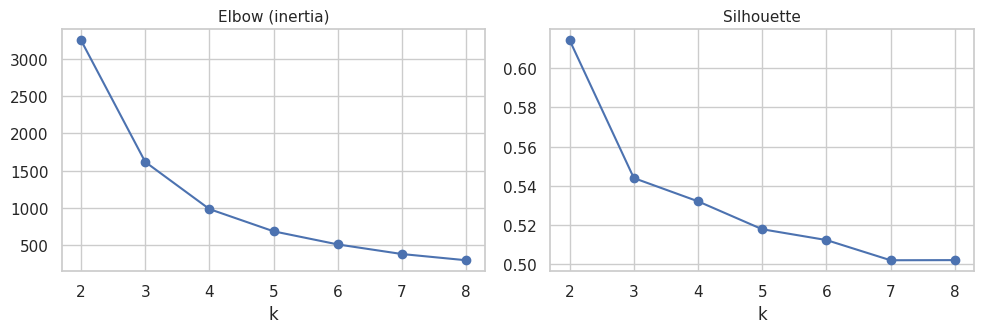

k chosen by silhouette: 2

Clustering comparison:


,method,clusters,noise_pct,silhouette
0,KMeans(k=2),2,0.0,0.614
1,"DBSCAN(eps=0.1, min=30)",2,3.2,0.538
2,BIRCH(k=2),2,0.0,0.625



Data-driven vs. physical regimes (row-normalised):


regime_phys,below cut-in,partial load,rated
regime,,,
0,0.00,0.92,0.08
1,0.17,0.83,0.00


Normal behaviour per regime (healthy rows):


Wind speed (m/s)        Power (kW)              \
                   mean  std         mean         std   
regime                                                  
0                   9.3  2.0  1424.500000  422.299988   
1                   4.7  1.6   274.299988  231.699997   

       Gear oil temperature (°C)       
                            mean  std  
regime                                 
0                      51.799999  2.6  
1                      53.599998  6.3

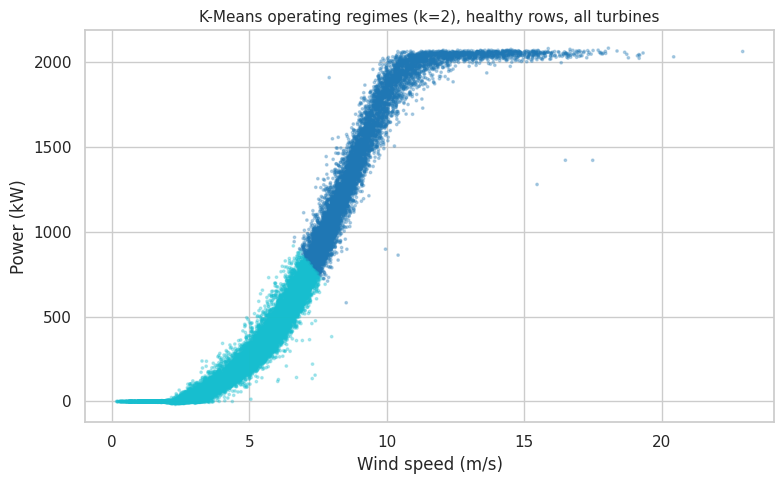

In [10]:
from sklearn.cluster import KMeans, DBSCAN, Birch
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

base = scada.loc[healthy_mask & scada[WIND].notna(), [WIND, POWER]]
if base.empty:
    raise ValueError("No healthy rows with both wind speed and power are available for regime analysis.")
sample = base.sample(min(5000, len(base)), random_state=SEED)  # DBSCAN is quadratic; keep this diagnostic bounded
scaler_reg = StandardScaler().fit(sample); X = scaler_reg.transform(sample)

rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(X, km.labels_, sample_size=5000, random_state=SEED)))
kdf = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(kdf.k, kdf.inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(kdf.k, kdf.silhouette, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
show("06_kmeans_k_selection")

K_REGIMES = int(kdf.loc[kdf.silhouette.idxmax(), "k"])   # override by hand if physics argues for 3
print("k chosen by silhouette:", K_REGIMES)

comp = [dict(method=f"KMeans(k={K_REGIMES})", clusters=K_REGIMES, noise_pct=0.0, silhouette=kdf.silhouette.max())]
db = DBSCAN(eps=0.1, min_samples=30).fit(X)
ok_ = db.labels_ != -1; ncl = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
comp.append(dict(method="DBSCAN(eps=0.1, min=30)", clusters=ncl, noise_pct=round((~ok_).mean() * 100, 1),
                 silhouette=silhouette_score(X[ok_], db.labels_[ok_], sample_size=min(5000, int(ok_.sum())), random_state=SEED) if ncl > 1 else np.nan))
bi = Birch(n_clusters=K_REGIMES).fit(X)
comp.append(dict(method=f"BIRCH(k={K_REGIMES})", clusters=K_REGIMES, noise_pct=0.0,
                 silhouette=silhouette_score(X, bi.labels_, sample_size=5000, random_state=SEED)))
print("\nClustering comparison:"); display(pd.DataFrame(comp).round(3))

km = KMeans(K_REGIMES, n_init=10, random_state=SEED).fit(X)
scada["regime"] = -1
ok = scada[WIND].notna() & scada[POWER].notna()
scada.loc[ok, "regime"] = km.predict(scaler_reg.transform(scada.loc[ok, [WIND, POWER]]))
scada["regime_phys"] = pd.cut(scada[WIND], [-np.inf, CUT_IN, RATED_WS, np.inf], labels=["below cut-in", "partial load", "rated"])

print("\nData-driven vs. physical regimes (row-normalised):")
display(pd.crosstab(scada.regime, scada.regime_phys, normalize="index").round(2))
print("Normal behaviour per regime (healthy rows):")
display(scada[healthy_mask].groupby("regime")[[WIND, POWER, GEAR]].agg(["mean", "std"]).round(1))

s = scada[healthy_mask].sample(min(30000, int(healthy_mask.sum())), random_state=SEED)
plt.figure(figsize=(8, 5)); plt.scatter(s[WIND], s[POWER], c=s.regime, cmap="tab10", s=3, alpha=0.3)
plt.xlabel("Wind speed (m/s)"); plt.ylabel("Power (kW)"); plt.title(f"K-Means operating regimes (k={K_REGIMES}), healthy rows, all turbines")
show("06_regimes")

## 7. Thermal behaviour and sensor coupling

**What to look for:** gear-oil temperature should rise with power and ambient temperature, and bearing temperature should track gear-oil temperature because the components are physically coupled. A turbine that runs hot at low power, or whose coupling weakens, is behaving abnormally. The table counts "hot at low load" rows per turbine (power < 500 kW and gear oil > 65 °C).

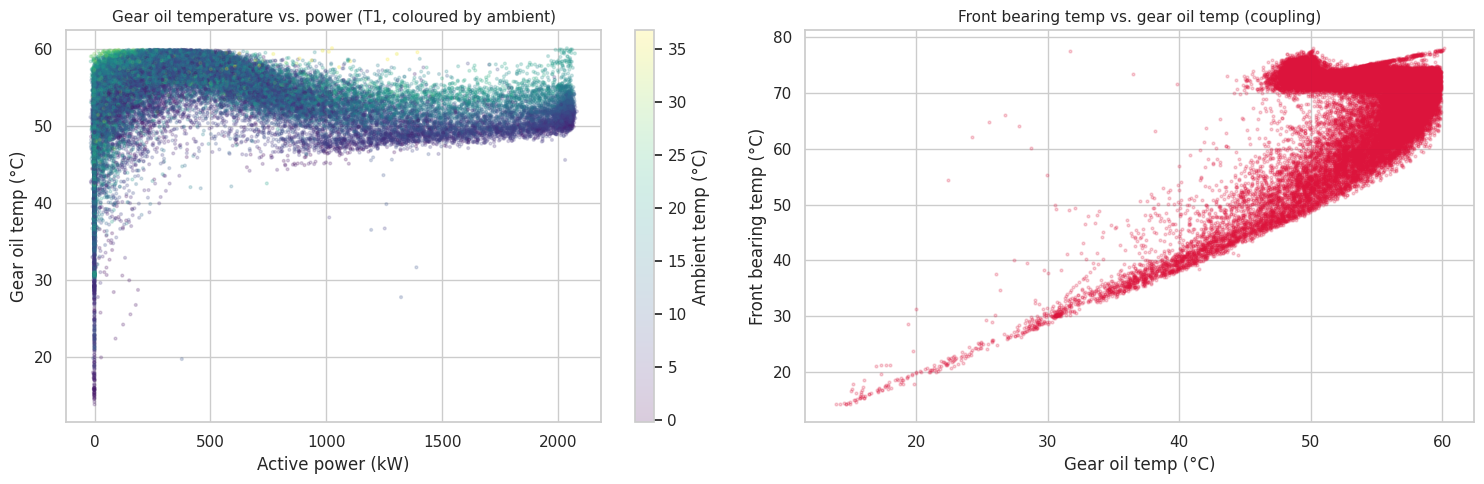

,"corr(gear, power)","corr(gear, bearing)",hot_at_low_load_rows
turbine,,,
1,-0.058,0.662,0.0
2,-0.002,0.741,0.0
3,-0.049,0.658,0.0
4,-0.043,0.707,0.0
5,0.057,0.773,0.0
6,0.041,0.699,0.0


In [11]:
s = scada[(scada.turbine == REF_T)].sample(min(40000, int((scada.turbine == REF_T).sum())), random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sc1 = ax[0].scatter(s[POWER], s[GEAR], c=s[AMB], cmap="viridis", s=4, alpha=0.2)
ax[0].set_title(f"Gear oil temperature vs. power (T{REF_T}, coloured by ambient)"); ax[0].set_xlabel("Active power (kW)"); ax[0].set_ylabel("Gear oil temp (°C)")
plt.colorbar(sc1, ax=ax[0]).set_label("Ambient temp (°C)")
ax[1].scatter(s[GEAR], s[BEAR], s=4, alpha=0.2, c="crimson")
ax[1].set_title("Front bearing temp vs. gear oil temp (coupling)"); ax[1].set_xlabel("Gear oil temp (°C)"); ax[1].set_ylabel("Front bearing temp (°C)")
show("07_thermal_coupling")

thermal = scada.groupby("turbine").apply(lambda g: pd.Series({
    "corr(gear, power)": g[GEAR].corr(g[POWER]),
    "corr(gear, bearing)": g[GEAR].corr(g[BEAR]),
    "hot_at_low_load_rows": int(((g[POWER] < 500) & (g[GEAR] > 65)).sum())})).round(3)
display(thermal)

## 8. Sensor correlation and redundancy

Two purposes: (1) the heatmap of core sensors shows cross-subsystem relationships, and (2) the list of near-duplicate channels shows how much redundancy PCA will have to absorb, which supports the dimensionality-reduction step.

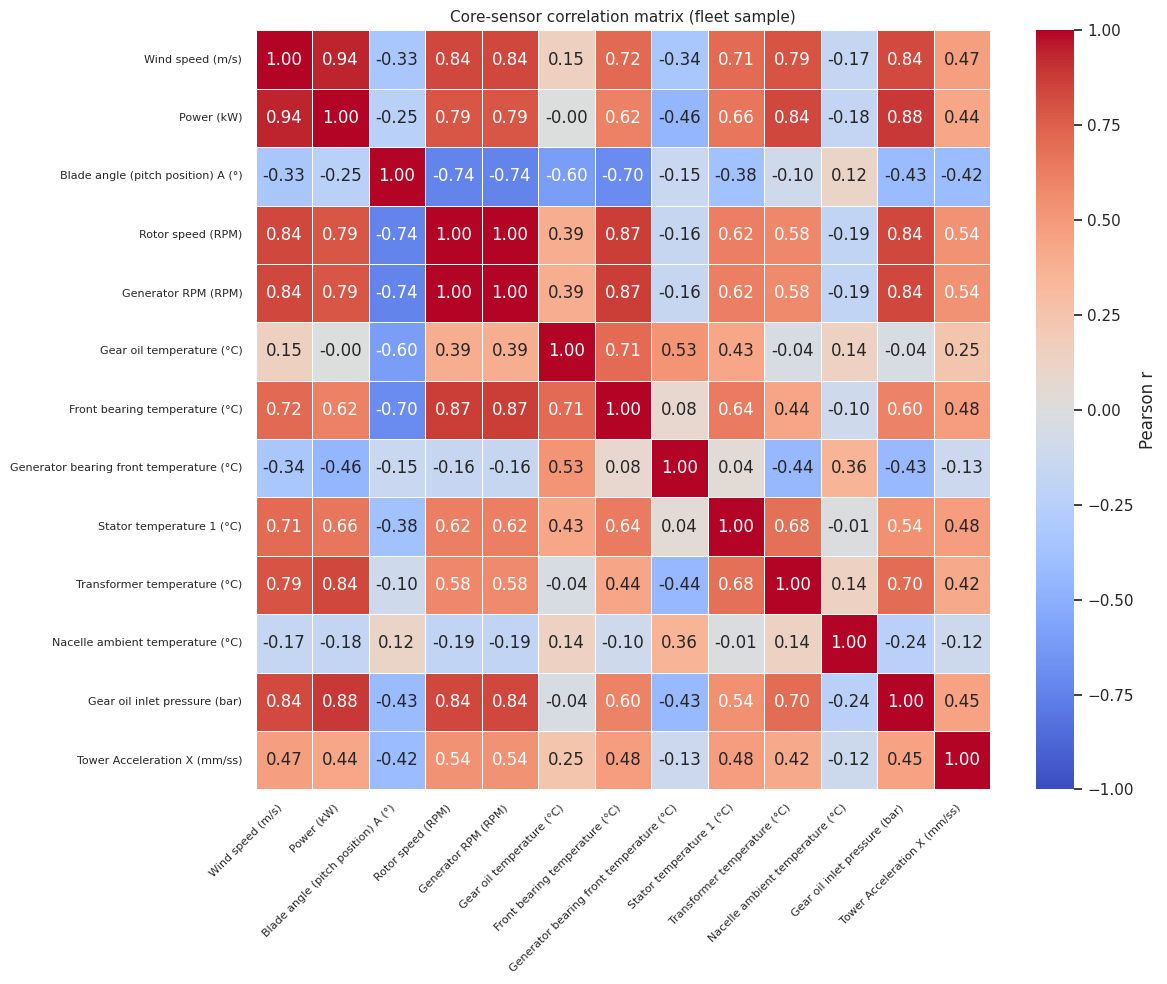

Channel pairs with |r| > 0.95: 95 of 3,001 possible pairs


,channel_a,channel_b,abs_corr
0,Production Factor,Performance Index,1.0
1,Nacelle position (°),Yaw bearing angle (°),1.0
2,Rotor speed (RPM),Gearbox speed (RPM),1.0
3,Current L1 / U (A),Grid current (A),1.0
4,Current L2 / V (A),Grid current (A),1.0
5,Current L1 / U (A),Current L2 / V (A),1.0
6,"Current L1 / U, max (A)","Current L2 / V, max (A)",1.0
7,Current L3 / W (A),Grid current (A),1.0
8,Current L1 / U (A),Current L3 / W (A),1.0
9,"Current L1 / U, max (A)","Current L3 / W, max (A)",1.0


In [12]:
samp = scada.sample(min(60000, len(scada)), random_state=SEED)
plt.figure(figsize=(12, 10))
sns.heatmap(samp[CORE].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "Pearson r"})
plt.title("Core-sensor correlation matrix (fleet sample)"); plt.xticks(rotation=45, ha="right", fontsize=8); plt.yticks(fontsize=8)
show("08_correlation_core")

corr = samp[RAW_SENSORS].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print(f"Channel pairs with |r| > 0.95: {(pairs > 0.95).sum()} of {len(pairs):,} possible pairs")
display(pairs.head(15).round(3).rename("abs_corr").reset_index().rename(columns={"level_0": "channel_a", "level_1": "channel_b"}))

## 9. Precursor analysis

**Why this needs more than a plot.** Temperatures normally fall when power falls, so a temperature drop before a stop does *not* by itself indicate a precursor; it may simply be low load. The test below removes the load effect:

1. A gradient-boosting **normal-behaviour model** predicts each temperature from power, rotor speed, ambient temperature and wind speed. It is trained on **healthy rows of the other turbines** (a sister-turbine baseline, which avoids time leakage).
2. The **residual** (actual minus predicted) is z-scored with the failing turbine's own healthy residuals.
3. The 24 h mean residual just before each failure is ranked against **random healthy 24 h windows** (empirical percentile). A value of 99 or more means the pre-failure period is unusual compared with ordinary days; below about 95 means no evidence of a precursor in that sensor.

**How to read the result.** A high percentile is a candidate precursor; a low percentile is *not* proof that no precursor exists. With only a handful of failure episodes (see the Section 5 gate), temperature-only sensors that are not part of the hydraulic system, overlapping (autocorrelated) 24 h windows in the placebo distribution and no correction for testing several sensors, this test has very little statistical power and should be reported as **inconclusive** rather than negative. The `r2_healthy` / `mae_healthy` columns show how well each normal-behaviour model reproduces healthy rows of the failing turbine; if R² is low, the residuals are mostly noise and the percentile means little.

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

NBM_FEATS = [c for c in [POWER, ROTOR, AMB, WIND] if c]
HYD = [c for c in RAW_SENSORS if "ydraulic" in c]
print("Hydraulic-related channels available:", HYD)
NBM_TARGETS = TARGETS + HYD[:2]
resid_z = {}
nbm_quality = {}      # (turbine, target) -> accuracy of the normal-behaviour model on that turbine's healthy rows

def fit_sister_nbm(T, target, max_rows=120_000):
    train = scada[healthy_mask & (scada.turbine != T) & scada[target].notna()]
    if len(train) > max_rows:
        train = train.sample(max_rows, random_state=SEED)
    m = HistGradientBoostingRegressor(max_iter=200, random_state=SEED).fit(train[NBM_FEATS], train[target])
    idx = scada.index[scada.turbine == T]
    pred = pd.Series(m.predict(scada.loc[idx, NBM_FEATS]), index=idx)
    res = scada.loc[idx, target] - pred
    ref = res[healthy_mask.loc[idx]]
    ok = (healthy_mask.loc[idx] & scada.loc[idx, target].notna()).values
    act = scada.loc[idx, target].values[ok]; prd = pred.values[ok]
    nbm_quality[(T, target)] = dict(r2_healthy=round(float(r2_score(act, prd)), 3) if ok.sum() > 1 else np.nan,
                                    mae_healthy=round(float(mean_absolute_error(act, prd)), 3) if ok.sum() else np.nan)
    return (res - ref.mean()) / ref.std()

def precursor_table():
    rows = []
    for T in sorted(episodes.turbine.unique()):
        idx = scada.index[scada.turbine == T]
        tt = scada.loc[idx, "Date and time"].values
        for tg in NBM_TARGETS:
            if (T, tg) not in resid_z:
                resid_z[(T, tg)] = fit_sister_nbm(T, tg)
            roll = resid_z[(T, tg)].rolling(144, min_periods=100).mean()          # 24 h mean z
            placebo = roll[healthy_mask.loc[idx]].dropna().abs()
            for _, ep in episodes[episodes.turbine == T].iterrows():
                pos = np.searchsorted(tt, np.datetime64(ep.t_fail)) - 1
                if pos < 0 or pd.isna(roll.iloc[pos]):
                    continue
                val = roll.iloc[pos]
                rows.append(dict(turbine=T, t_fail=ep.t_fail, message=ep.message, sensor=tg,
                                 mean_z_24h_before=round(float(val), 2),
                                 pctile_vs_healthy=round(float((placebo < abs(val)).mean() * 100), 1),
                                 **nbm_quality.get((T, tg), {})))
    return pd.DataFrame(rows)

prec = pd.DataFrame()
if len(episodes):
    prec = precursor_table()
    pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
    display(prec.sort_values("pctile_vs_healthy", ascending=False))
    print(f"\nPOWER CAVEAT: {len(episodes)} episode(s) on {episodes.turbine.nunique()} turbine(s); "
          f"hydraulic channels available: {bool(HYD)}; {len(NBM_TARGETS)} sensors tested, no multiple-testing correction. "
          "Treat a low percentile as INCONCLUSIVE, not as absence of a precursor.")
    weak = prec[prec.r2_healthy < 0.5] if "r2_healthy" in prec else prec.iloc[0:0]
    if len(weak):
        print(f"WARNING: normal-behaviour model R2 < 0.5 for {len(weak)} of {len(prec)} rows: residuals there are mostly noise.")
else:
    print("No failure episodes: revisit the anchor rule in section 5.")

Hydraulic-related channels available: []


,turbine,t_fail,message,sensor,mean_z_24h_before,pctile_vs_healthy,r2_healthy,mae_healthy
2,1,2019-02-24 02:31:49,Low hydraulic pressure,Front bearing temperature (°C),0.60,89.0,0.897,2.004
0,1,2019-02-24 02:31:49,Low hydraulic pressure,Gear oil temperature (°C),0.58,83.3,0.636,2.199
1,1,2019-03-27 20:32:14,Low hydraulic pressure,Gear oil temperature (°C),0.51,79.0,0.636,2.199
3,1,2019-03-27 20:32:14,Low hydraulic pressure,Front bearing temperature (°C),0.39,78.5,0.897,2.004
6,1,2019-02-24 02:31:49,Low hydraulic pressure,Stator temperature 1 (°C),0.29,75.7,0.733,2.628
4,1,2019-02-24 02:31:49,Low hydraulic pressure,Generator bearing front temperature (°C),0.35,70.4,0.470,2.999
7,1,2019-03-27 20:32:14,Low hydraulic pressure,Stator temperature 1 (°C),0.16,51.8,0.733,2.628
5,1,2019-03-27 20:32:14,Low hydraulic pressure,Generator bearing front temperature (°C),0.07,18.5,0.470,2.999



POWER CAVEAT: 2 episode(s) on 1 turbine(s); hydraulic channels available: False; 4 sensors tested, no multiple-testing correction. Treat a low percentile as INCONCLUSIVE, not as absence of a precursor.


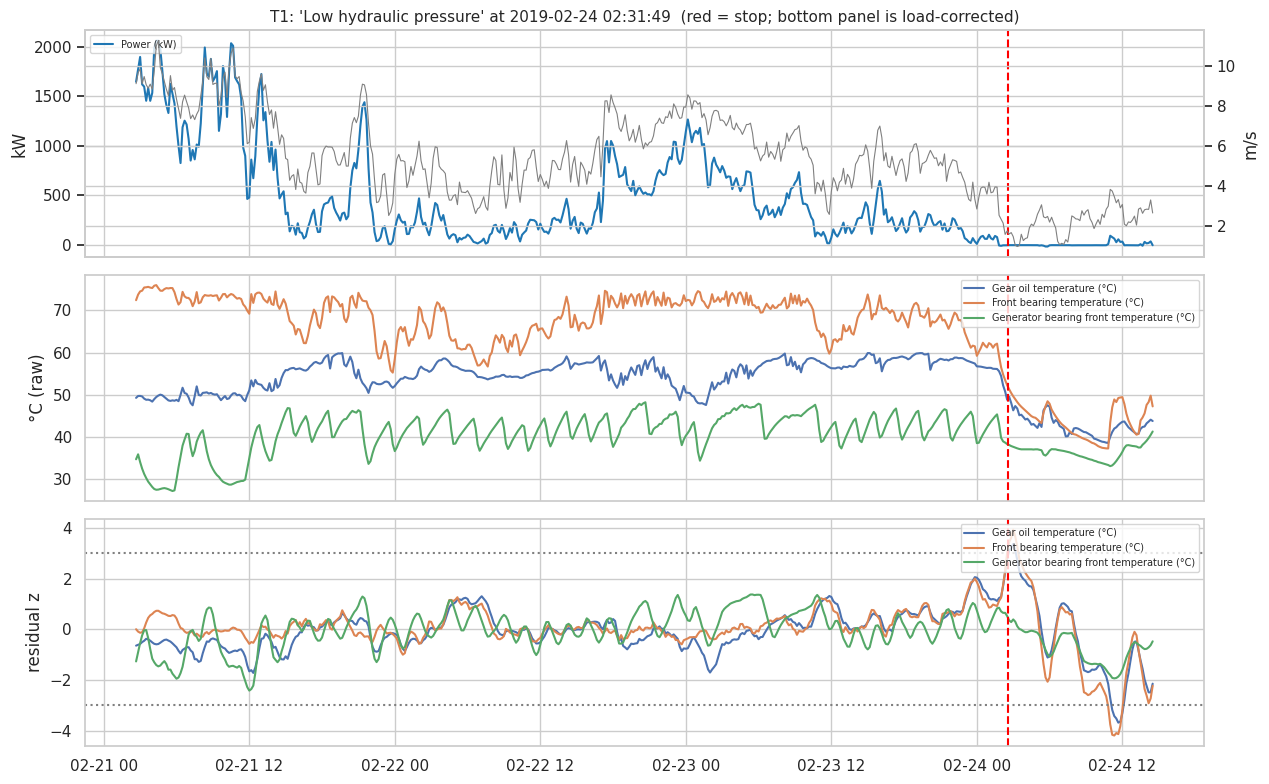

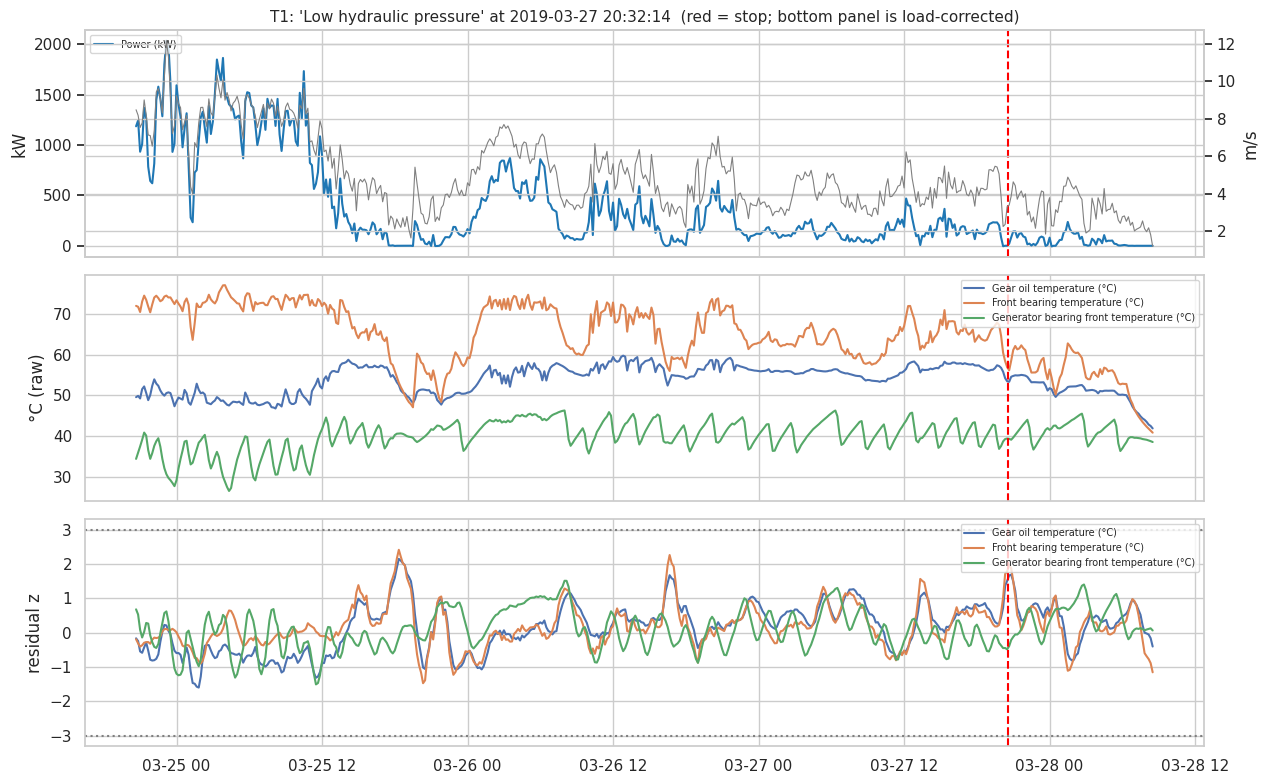

In [14]:
# Episode plots: raw behaviour (what you see) vs. load-corrected residual (what the test uses)
for _, ep in episodes.head(MAX_EPISODE_PLOTS).iterrows():
    idx = scada.index[scada.turbine == ep.turbine]
    d = scada.loc[idx]; tt = d["Date and time"]
    win = (tt >= ep.t_fail - pd.Timedelta(days=3)) & (tt <= ep.t_fail + pd.Timedelta(hours=12))
    fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    ax[0].plot(tt[win], d.loc[win, POWER], color="tab:blue", label="Power (kW)")
    ax2 = ax[0].twinx(); ax2.plot(tt[win], d.loc[win, WIND], color="grey", lw=0.8, label="Wind (m/s)"); ax2.set_ylabel("m/s")
    ax[0].set_ylabel("kW"); ax[0].legend(loc="upper left", fontsize=7)
    for tg in TARGETS[:3]:
        ax[1].plot(tt[win], d.loc[win, tg], label=tg)
    ax[1].set_ylabel("°C (raw)"); ax[1].legend(fontsize=7, loc="upper right")
    for tg in NBM_TARGETS[:3]:
        z = resid_z.get((ep.turbine, tg))
        if z is not None:
            ax[2].plot(tt[win], z.rolling(6, min_periods=3).mean()[win], label=tg)
    ax[2].axhline(3, color="grey", ls=":"); ax[2].axhline(-3, color="grey", ls=":")
    ax[2].set_ylabel("residual z"); ax[2].legend(fontsize=7, loc="upper right")
    for a in ax: a.axvline(ep.t_fail, color="red", ls="--", lw=1.5)
    ax[0].set_title(f"T{ep.turbine}: '{ep.message}' at {ep.t_fail}  (red = stop; bottom panel is load-corrected)")
    show(f"09_episode_T{ep.turbine}_{ep.t_fail:%Y%m%d}")

## 10. Window features

The classifiers will not see single 10-minute rows but short windows. For each key sensor, a 6 h rolling **mean**, **standard deviation** and **net trend per step** are computed per turbine (no leakage across turbines).

In [15]:
KEY = [c for c in [WIND, POWER, ROTOR, AMB] + TARGETS + ["power_dev"] if c]
def add_window_feats(df, w=36):
    g = df.groupby("turbine"); out = {}
    for c in KEY:
        r = g[c].rolling(w, min_periods=int(w * 0.7))
        out[f"{c}__mean{w}"]  = r.mean().reset_index(level=0, drop=True)
        out[f"{c}__std{w}"]   = r.std().reset_index(level=0, drop=True)
        out[f"{c}__trend{w}"] = (df[c] - g[c].shift(w - 1)) / (w - 1)
    return pd.DataFrame(out, index=df.index).astype("float32")

WIN_FEATS = add_window_feats(scada)
print("Window feature matrix:", WIN_FEATS.shape, "| missing share:", round(float(WIN_FEATS.isna().mean().mean()) * 100, 2), "%")

Window feature matrix: (315360, 27) | missing share: 0.48 %


## 11. PCA and Kernel PCA

Scaler, imputer and PCA are fitted on **healthy rows from the first 70 % of the timeline only**, so nothing from the later period or from failure episodes leaks into the transform. The key diagnostic is the left plot: do pre-failure rows (red) separate from normal rows in the leading components?

67 of 78 channels kept (<20% missing on train, non-constant). Train rows available: 215,027 | used to fit: 215,027
Components for 95% variance: 17 | for 99%: 30


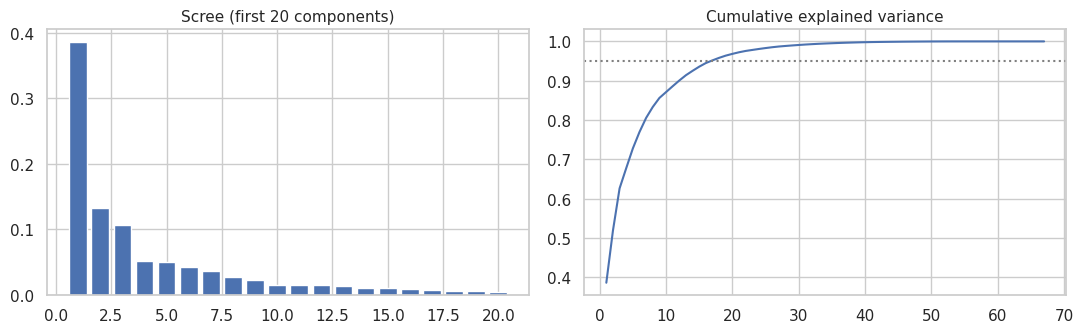


Top loadings, PC1:


,PC1
Current L2 / V (A),0.189
Grid current (A),0.189
Current L1 / U (A),0.189
Current L3 / W (A),0.189
Apparent power (kVA),0.189
Density adjusted wind speed (m/s),0.188



Top loadings, PC2:


,PC2
Rotor bearing temp (°C),0.280
Generator bearing rear temperature (°C),0.276
Ambient temperature (converter) (°C),0.266
Hub temperature (°C),0.265
Transformer cell temperature (°C),0.263
Nacelle ambient temperature (°C),0.261



Top loadings, PC3:


,PC3
Blade angle (pitch position) B (°),0.252
Blade angle (pitch position) C (°),0.252
Blade angle (pitch position) A (°),0.252
Temperature motor axis 1 (°C),0.240
Temperature motor axis 2 (°C),0.239
Temperature motor axis 3 (°C),0.238


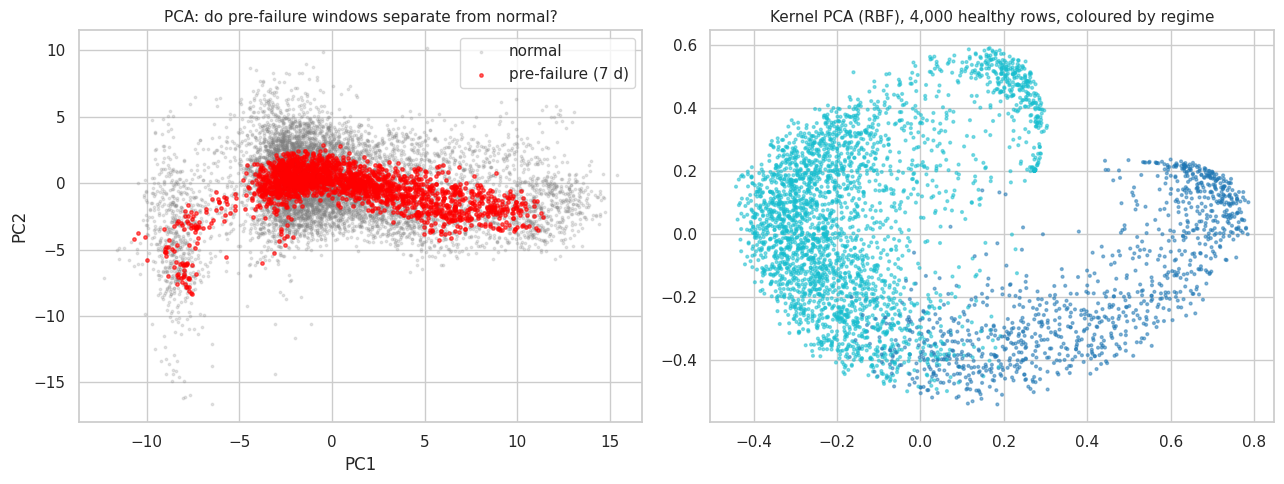

In [16]:
from sklearn.decomposition import PCA, KernelPCA
from sklearn.impute import SimpleImputer

times = np.sort(scada["Date and time"].unique())
cut = times[int(0.7 * len(times))]
train_mask = (scada["Date and time"] < cut) & healthy_mask

# Fit imputer / scaler / PCA on a bounded random sample of the training period (keeps memory in check with many years)
FIT_MAX = 300_000
tr_idx = scada.index[train_mask]
if len(tr_idx) > FIT_MAX:
    tr_idx = np.random.default_rng(SEED).choice(tr_idx, FIT_MAX, replace=False)
Xtr = scada.loc[tr_idx, RAW_SENSORS]
keep = [c for c in RAW_SENSORS if Xtr[c].isna().mean() < 0.2 and Xtr[c].std() > 0]
if not keep:
    raise ValueError("No usable channels for PCA: check the healthy_mask and channel filters.")
print(f"{len(keep)} of {len(RAW_SENSORS)} channels kept (<20% missing on train, non-constant). "
      f"Train rows available: {int(train_mask.sum()):,} | used to fit: {len(Xtr):,}")

imp = SimpleImputer(strategy="median").fit(Xtr[keep])
sc  = StandardScaler().fit(imp.transform(Xtr[keep]))
pca = PCA(random_state=SEED).fit(sc.transform(imp.transform(Xtr[keep])))
cum = np.cumsum(pca.explained_variance_ratio_)
n95, n99 = int(np.searchsorted(cum, 0.95) + 1), int(np.searchsorted(cum, 0.99) + 1)
print(f"Components for 95% variance: {n95} | for 99%: {n99}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
nshow = min(20, len(cum))
ax[0].bar(range(1, nshow + 1), pca.explained_variance_ratio_[:nshow]); ax[0].set_title("Scree (first 20 components)")
ax[1].plot(range(1, len(cum) + 1), cum); ax[1].axhline(0.95, color="grey", ls=":"); ax[1].set_title("Cumulative explained variance")
show("11_pca_variance")

load = pd.DataFrame(pca.components_[:3].T, index=keep, columns=["PC1", "PC2", "PC3"])
for c in load.columns:
    print(f"\nTop loadings, {c}:"); display(load[c].reindex(load[c].abs().sort_values(ascending=False).index).head(6).round(3))

def project(df_):
    return pca.transform(sc.transform(imp.transform(df_[keep])))

normal_s = scada[healthy_mask].sample(min(8000, int(healthy_mask.sum())), random_state=SEED)
pre_s = scada[scada.label == 1]
pre_s = pre_s.sample(min(8000, len(pre_s)), random_state=SEED) if len(pre_s) else pre_s
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pn = project(normal_s); ax[0].scatter(pn[:, 0], pn[:, 1], s=3, alpha=0.2, c="grey", label="normal")
if len(pre_s):
    pp = project(pre_s); ax[0].scatter(pp[:, 0], pp[:, 1], s=6, alpha=0.6, c="red", label=f"pre-failure ({PRE_DAYS} d)")
ax[0].set_title("PCA: do pre-failure windows separate from normal?"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()

kp_s = scada[train_mask].sample(min(4000, int(train_mask.sum())), random_state=SEED)
kp = KernelPCA(n_components=2, kernel="rbf", gamma=1 / len(keep), random_state=SEED)
Zk = kp.fit_transform(sc.transform(imp.transform(kp_s[keep])))
ax[1].scatter(Zk[:, 0], Zk[:, 1], c=kp_s.regime, cmap="tab10", s=4, alpha=0.5)
ax[1].set_title("Kernel PCA (RBF), 4,000 healthy rows, coloured by regime")
show("11_pca_vs_kernel_pca")


## 12. Distributions, seasonality and turbine-to-turbine offsets

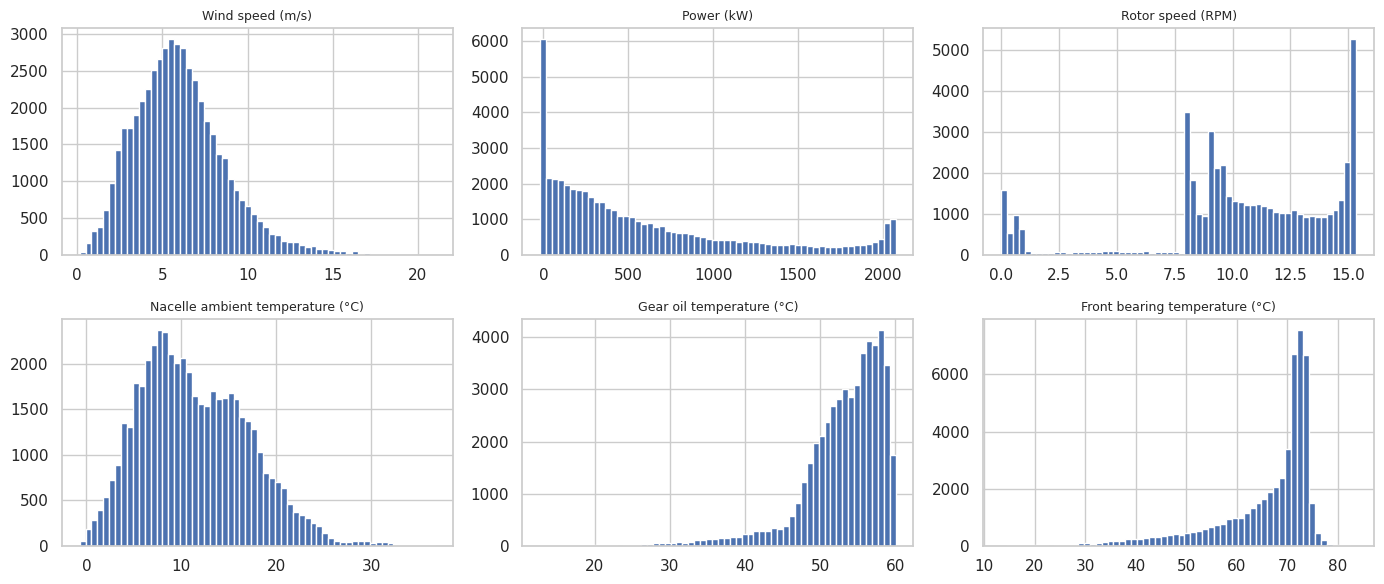

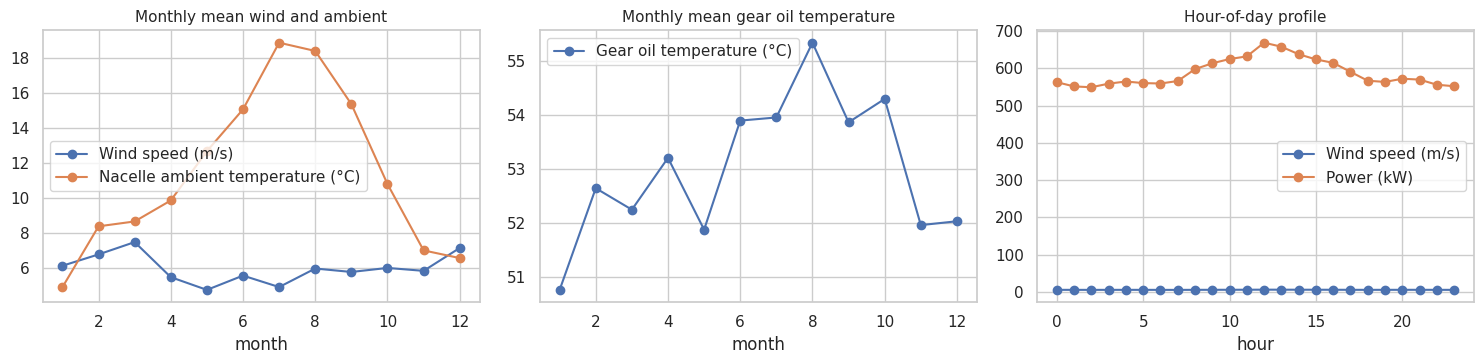

Autocorrelation of gear oil temp by lag (10-min steps), informs window length and split gaps:
{1: 0.98, 6: 0.926, 36: 0.573, 144: 0.141, 1008: 0.03}


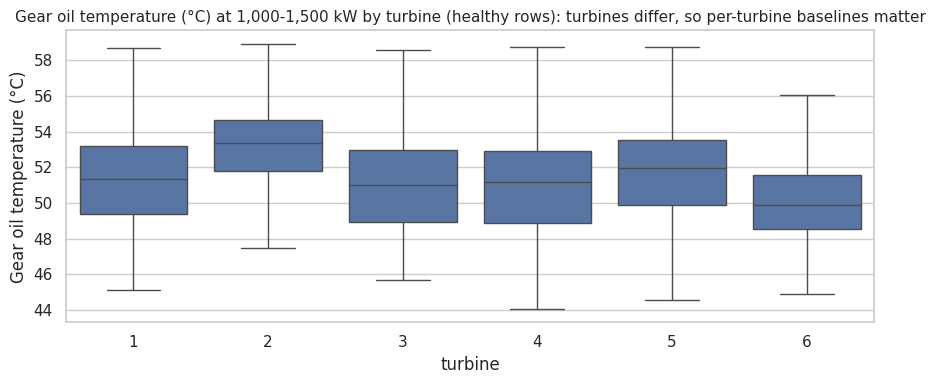

In [17]:
cols = [c for c in [WIND, POWER, ROTOR, AMB, GEAR, BEAR] if c]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), cols):
    scada[c].dropna().sample(min(50000, int(scada[c].notna().sum())), random_state=SEED).hist(bins=60, ax=ax); ax.set_title(c, fontsize=9)
show("12_distributions")

d = scada.assign(month=scada["Date and time"].dt.month, hour=scada["Date and time"].dt.hour)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
d.groupby("month")[[WIND, AMB]].mean().plot(ax=ax[0], marker="o", title="Monthly mean wind and ambient")
d.groupby("month")[[GEAR]].mean().plot(ax=ax[1], marker="o", title="Monthly mean gear oil temperature")
d.groupby("hour")[[WIND, POWER]].mean().plot(ax=ax[2], marker="o", title="Hour-of-day profile")
show("12_seasonality")

g1 = scada[scada.turbine == REF_T][GEAR].dropna()
print("Autocorrelation of gear oil temp by lag (10-min steps), informs window length and split gaps:")
print({lag: round(float(g1.autocorr(lag)), 3) for lag in [1, 6, 36, 144, 1008]})

sub = scada[healthy_mask & scada[POWER].between(1000, 1500)]
plt.figure(figsize=(9, 4)); sns.boxplot(data=sub, x="turbine", y=GEAR, showfliers=False)
plt.title(f"{GEAR} at 1,000-1,500 kW by turbine (healthy rows): turbines differ, so per-turbine baselines matter")
show("12_turbine_offsets")

## 13. Cross-farm channel overlap (Kelmarsh vs. Penmanshiel)

The project trains on Kelmarsh and tests on Penmanshiel without retraining, so only channels present in **both** farms can be used as features. This section reads the Penmanshiel header and saves the shared channel list for the team.

In [18]:
COMMON_COLS = None
try:
    files = zenodo_files(PENMANSHIEL_RECORD)
    key = next(k for k in files if k.startswith("Penmanshiel_SCADA_2019") and k.endswith(".zip"))
    z = f"{BASE}/{key}"; fetch(files[key], z)
    pdir = f"{BASE}/extracted_penmanshiel_2019"; os.makedirs(pdir, exist_ok=True)
    with zipfile.ZipFile(z) as zf: zf.extractall(pdir)
    p = sorted(glob.glob(f"{pdir}/**/Turbine_Data_Penmanshiel_*.csv", recursive=True))[0]
    i = _header_idx(p, "Date and time")
    pen_cols = [c.replace("# ", "").strip() for c in pd.read_csv(p, skiprows=i, nrows=0).columns]
    pen_cols = [c for c in pen_cols if not any(s in c for s in EXCLUDE_IN_NAME)]
    COMMON_COLS = sorted(set(pen_cols) & set(RAW_SENSORS))
    print(f"Kelmarsh channels: {len(RAW_SENSORS)} | Penmanshiel: {len(pen_cols)} | common: {len(COMMON_COLS)}")
    for c in [WIND, POWER, ROTOR, AMB] + TARGETS:
        print(f"  {'OK     ' if c in COMMON_COLS else 'MISSING'} {c}")
    json.dump(COMMON_COLS, open(f"{BASE}/common_cols_kelmarsh_penmanshiel.json", "w"))
except Exception as e:
    print("Penmanshiel check skipped:", repr(e)[:200])

Penmanshiel check skipped: HTTPError('403 Client Error: Forbidden for url: https://zenodo.org/api/records/16807304')


## 14. Leakage-safe evaluation design and modeling handoff

This EDA does not claim model performance. Before training, agree on the deployment question (for example, “raise an alert when a low-hydraulic-pressure stop is expected within 24 hours”), the acceptable alert burden, and whether evaluation must generalize to future dates, unseen turbines, or a new farm. The current `PRE_DAYS=7` label is a hypothesis; compare the sensitivity table and select the horizon before model selection.

Use a **time-based holdout** for future prediction. All turbines should share the same calendar cut so a timestamp cannot appear in both partitions. Keep a purge/embargo at least as long as the label horizon plus the feature lookback (6 h in this notebook). Group all rows from the same failure episode together. Fit imputers, scalers, feature selection, resampling, and thresholds on training data only. Do not randomly split 10-minute rows: adjacent rows and overlapping windows are highly dependent.

If there are too few independent failure episodes in the held-out period, report that performance cannot be estimated reliably. Do not move episodes between train and test to make scores look better. For a cross-farm claim, use Penmanshiel as a separately held-out external test only after checking its event labels, time coverage, sensor semantics, and the shared feature set; channel-name overlap alone is not validation.

The next modeling stage should compare a simple operational baseline, a normal-behaviour/anomaly approach, and (only if independent events support it) a supervised classifier. Report event-level recall, false alarms per turbine-day, alert lead time, precision-recall metrics, and uncertainty across episodes; row-level accuracy is not an adequate headline metric for rare failures. Resampling and threshold tuning belong inside training folds only.

In [19]:
# Compact handoff table: event counts and whether a future holdout is even possible.
if len(episodes):
    ep_by_time = episodes.sort_values("t_fail").copy()
    cut_time = scada["Date and time"].quantile(0.8)
    embargo = pd.Timedelta(days=PRE_DAYS) + pd.Timedelta(hours=6)
    train_eps = ep_by_time[ep_by_time.t_fail < cut_time - embargo]
    test_eps = ep_by_time[ep_by_time.t_fail >= cut_time + embargo]
    print(f"Provisional shared time cut (80th percentile): {cut_time}")
    print(f"Purge/embargo around cut: {embargo}")
    print(f"Independent episodes before cut: {len(train_eps)} | after cut: {len(test_eps)}")
    print("This is a feasibility check, not a final split. Inspect episode distribution and freeze the cut before modeling.")
else:
    print("No confirmed failure episodes: no supervised split can be constructed.")

handoff = {
    "target_messages": FAULT_MESSAGES,
    "pre_failure_days": PRE_DAYS,
    "post_event_exclusion_days": POST_BUFFER_DAYS,
    "minimum_stop_minutes": MIN_STOP_MIN,
    "feature_lookback_hours": 6,
    "independent_failure_episodes": int(len(episodes)),
    "turbines": int(scada.turbine.nunique()),
    "years": sorted(scada.year.unique().tolist()),
}
print("\nModeling handoff:")
display(pd.Series(handoff, name="value").to_frame())

Provisional shared time cut (80th percentile): 2019-10-19 23:52:00
Purge/embargo around cut: 7 days 06:00:00
Independent episodes before cut: 2 | after cut: 0
This is a feasibility check, not a final split. Inspect episode distribution and freeze the cut before modeling.

Modeling handoff:


,value
target_messages,[Low hydraulic pressure]
pre_failure_days,7
post_event_exclusion_days,1
minimum_stop_minutes,5
feature_lookback_hours,6
independent_failure_episodes,2
turbines,6
years,[2019]


## 15. Summary of findings
The cell below prints the key numbers and an automatic read-out of what the data supports. **Replace the template underneath with your own interpretation** of each point; this is what goes into the report and the viva.

In [20]:
g = globals()
facts = {
    "Turbines / years": f"{scada.turbine.nunique()} / {sorted(scada.year.unique().tolist())}",
    "SCADA rows (10-min)": f"{len(scada):,}",
    "Mean-only sensor channels": len(RAW_SENSORS),
    "Healthy rows (strict mask)": f"{int(healthy_mask.sum()):,}",
    "Failure episodes (anchors)": len(episodes),
    f"Pre-failure rows (N={PRE_DAYS} d)": f"{int(scada.label.sum()):,} ({scada.label.mean()*100:.3f}%)",
    "Operating regimes (silhouette)": K_REGIMES,
    "PCA components for 95% / 99% variance": f"{n95} / {n99}",
    "Channels common with Penmanshiel": len(COMMON_COLS) if COMMON_COLS else "not checked",
}
for k, v in facts.items():
    print(f"{k:40s} {v}")

print("\nAutomatic read-out:")
if len(episodes) >= 20:
    print(f"- {len(episodes)} failure episodes: enough to attempt supervised classification with turbine-wise splits.")
else:
    print(f"- Only {len(episodes)} failure episodes: supervised models, RUL regression and bootstrap CIs are not reliable; "
          "lead with anomaly detection / normal-behaviour modelling, or add years / the EDP logbook.")
if len(prec):
    hits = prec[prec.pctile_vs_healthy >= 99]
    if len(hits):
        b = hits.sort_values("pctile_vs_healthy", ascending=False).iloc[0]
        print(f"- Precursor test: {len(hits)} of {len(prec)} (episode, sensor) pairs exceed the 99th percentile of healthy days; "
              f"strongest: T{b.turbine} {b.sensor} before {b.t_fail}. Not corrected for multiple comparisons; treat as a lead to investigate.")
    else:
        print("- Precursor test: no (episode, sensor) pair exceeds the 99th percentile of healthy days. This is INCONCLUSIVE, "
              f"not evidence of absence: only {len(episodes)} episode(s) on {episodes.turbine.nunique()} turbine(s), "
              f"{'no hydraulic channels exist' if not HYD else 'hydraulic channels included'}, "
              "temperature sensors only, overlapping placebo windows, no multiple-testing correction.")
    if "r2_healthy" in prec:
        print(f"- Normal-behaviour model accuracy on healthy rows: median R2 = {prec.r2_healthy.median():.2f}, "
              f"median MAE = {prec.mae_healthy.median():.2f} (sensor units); low R2 means the residuals are mostly noise.")
print(f"- Imbalance is about 1:{(len(scada)-int(scada.label.sum()))/max(int(scada.label.sum()),1):,.0f}; use class weights / resampling inside training folds only.")

Turbines / years                         6 / [2019]
SCADA rows (10-min)                      315,360
Mean-only sensor channels                78
Healthy rows (strict mask)               308,580
Failure episodes (anchors)               2
Pre-failure rows (N=7 d)                 2,016 (0.639%)
Operating regimes (silhouette)           2
PCA components for 95% / 99% variance    17 / 30
Channels common with Penmanshiel         not checked

Automatic read-out:
- Only 2 failure episodes: supervised models, RUL regression and bootstrap CIs are not reliable; lead with anomaly detection / normal-behaviour modelling, or add years / the EDP logbook.
- Precursor test: no (episode, sensor) pair exceeds the 99th percentile of healthy days. This is INCONCLUSIVE, not evidence of absence: only 2 episode(s) on 1 turbine(s), no hydraulic channels exist, temperature sensors only, overlapping placebo windows, no multiple-testing correction.
- Normal-behaviour model accuracy on healthy rows: median R2 = 0.68

### Findings (write in your own words)
1. **Data quality:** which sensors and periods are unreliable (missing outage dates, frozen channels), and how you handled them.
2. **Labels:** the final failure-anchor rule, the number of real failure episodes, and whether supervised learning is viable.
3. **Normal behaviour:** what the power curve, regimes and thermal coupling look like, and how much turbines differ from each other.
4. **Precursor evidence:** what the load-corrected test showed, and what that means for the project's central claim.
5. **Features and dimensionality:** which engineered features and how many principal components the models will use.
6. **Cross-farm limits:** which channels survive the Kelmarsh to Penmanshiel mapping.
7. **Implications for modelling:** framing (anomaly detection first vs. classification), split strategy and imbalance handling.